In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
# read in data without weekend results
df = pd.read_csv('big12.csv')

# 16 teams no wonder its called the big 12
m = 16
# given
w = 1

# calculate h as given in problem statement
def h_func(S,T):
    x = (S + 1)/(S+T+2)
    h = 0.5 + 0.5 * np.sign(x - 0.5) * np.sqrt(np.abs(2*x - 1))
    return h

def priors(prior_type, m):
    # 1 - flat, 2 - last season, 3 - uniformly random strengths
    if prior_type == 1:
        Pi = 0.5 * np.ones((m,m))
    elif prior_type == 2:
        mean_h = np.zeros((m,m))
        counts_25 = np.zeros((m,m))
        # iterate over every row if completed game in 2025 then add to the mean
        for _, row in games_25.iterrows():
            if row['completed'] == 1:
                i = teams_idx.get(row['home'])
                j = teams_idx.get(row['away'])
                mean_h[i,j] += h_func(row['home_pts'], row['away_pts'])
                counts_25[i,j] += 1
        for k in range(m):
            for l in range(m):
                if counts_25[k,l] > 0:
                    # if they did play a game make the mean (avoids a divide by zero)
                    mean_h[k,l] = mean_h[k,l] / counts_25[k,l]
                else:
                    mean_h[k,l] = 0.5
        Pi = mean_h
    elif prior_type == 3:
        Pi = np.zeros((m,m))
        # make up random strengths just for funsies and count that as the preseason poll or whatnot
        s = np.random.uniform(0, 1, m)
        for k in range(m):
            for l in range(m):
                if k == l:
                    continue
                Pi[k,l] = s[k] / (s[k] + s[l])
    return Pi

r-values
| 0.06453, BYU | 0.06116, Iowa State |
| 0.06248, Oklahoma State | 0.06407, UCF |
| 0.06433, Houston | 0.06248, Kansas State |
| 0.06551, Arizona | 0.06063, West Virginia |
| 0.06091, Kansas | 0.06248, Utah |
Prior: 1
lambda* = 0.5001, |lambda2/lambda*| = 0.1163


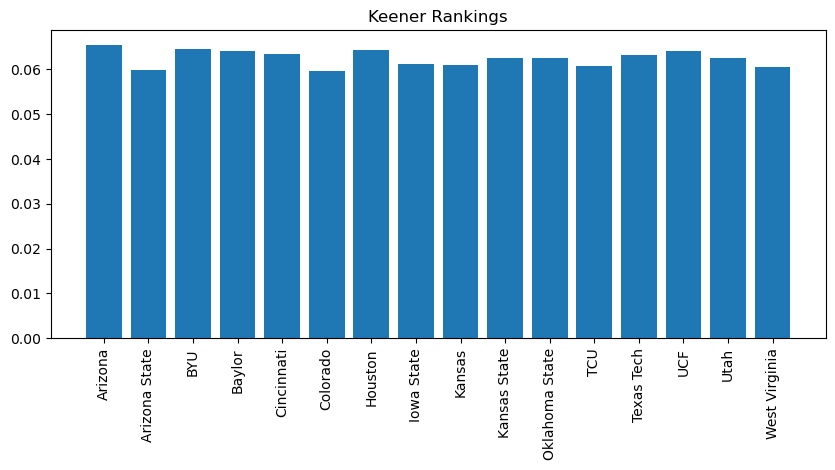

r-values
| 0.07145, BYU | 0.06205, Iowa State |
| 0.05075, Oklahoma State | 0.06464, UCF |
| 0.06103, Houston | 0.06349, Kansas State |
| 0.07040, Arizona | 0.05229, West Virginia |
| 0.05922, Kansas | 0.06778, Utah |
Prior: 2
lambda* = 0.5061, |lambda2/lambda*| = 0.1183


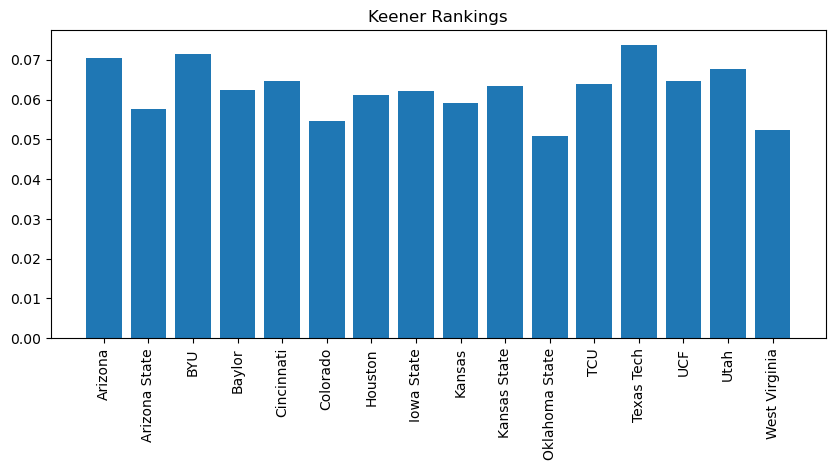

r-values
| 0.08342, BYU | 0.06036, Iowa State |
| 0.02157, Oklahoma State | 0.08272, UCF |
| 0.07068, Houston | 0.02656, Kansas State |
| 0.08368, Arizona | 0.08454, West Virginia |
| 0.08234, Kansas | 0.05291, Utah |
Prior: 3
lambda* = 0.4382, |lambda2/lambda*| = 0.1226


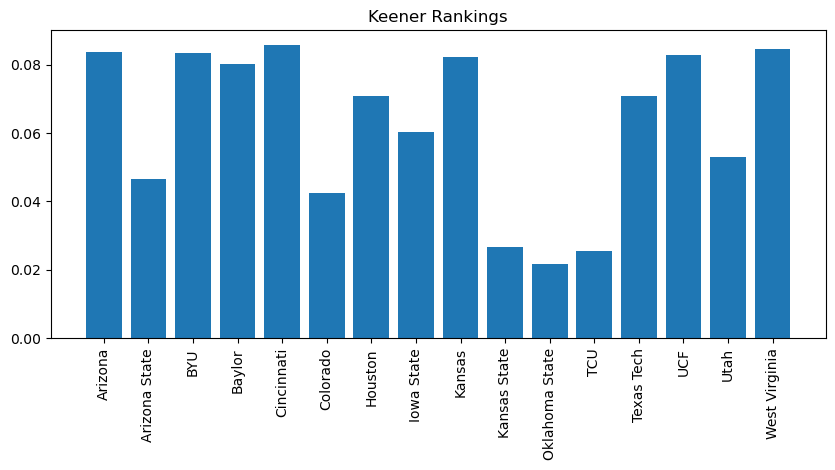

In [ ]:
# just a silly funny way of getting a list of all the unique teams in the data
teams = sorted(list(set(df['home']).union(set(df['away']))))
# give them all an index so we can actually use them without dealing with strings
teams_idx = {team: i for i, team in enumerate(teams)}

# separate out the games for each season (bc 2026 still in progress, we also need to check completed)
games_26 = df[(df['season'] == 2026) & (df['completed'] == 1)]
games_25 = df[df['season'] == 2025]

# for the first term in the numerator of a_{ij}
H_sum = np.zeros((m,m))
# number of times teams played each other (should generally be 0 or 1 bc matrix)
counts = np.zeros((m,m))

# fill those sums besties
for _, row in games_26.iterrows():
    if row['completed'] == 1:
        i = teams_idx[row['home']]
        j = teams_idx[row['away']]
        S = row['home_pts']
        T = row['away_pts']
        val = h_func(S,T)
        H_sum[i,j] += val
        counts[i,j] += 1

# do everything for each and hope it works
for prior_type in [1,2,3]:
    Pi = priors(prior_type, m)
    # matrix we are actually looking at the eigs for
    A = np.zeros((m,m))
    for i in range(m):
        # how many games has this team played (sum over all the j's)
        ni = np.sum(counts[i, :])
        denom = ni + w * (m-1)
        for j in range(m):
            if denom == 0:
                A[i,j] = 0
            elif i != j:
                # if i=j a team doesn't play itself so that just stays zero
                A[i,j] = (H_sum[i,j] + w * Pi[i,j])/denom

    # get the eigs, sort them and order them
    eigs, vecs = np.linalg.eig(A)
    idx = np.argsort(np.abs(eigs))[::-1]
    eigs = eigs[idx]
    vecs = vecs[:, idx]

    # what we are actually here for - no imaginary part anyways but to avoid the +0.00000j stuff
    lambd1 = eigs[0].real
    lambd2 = eigs[1].real
    ratio = abs(lambd2/lambd1)

    r = np.abs(vecs[:, 0])
    r = r / np.sum(r)
    print(f'r-values')
    # games weekend of Oct 10-11 (could have written code just compared by hand... sue me)
    print(f'| {r[2]:.5f}, {teams[2]} | {r[7]:.5f}, {teams[7]} |')
    print(f'| {r[10]:.5f}, {teams[10]} | {r[13]:.5f}, {teams[13]} |')
    print(f'| {r[6]:.5f}, {teams[6]} | {r[9]:.5f}, {teams[9]} |')
    print(f'| {r[0]:.5f}, {teams[0]} | {r[15]:.5f}, {teams[15]} |')
    print(f'| {r[8]:.5f}, {teams[8]} | {r[14]:.5f}, {teams[14]} |')


    # print the other stuff we care about (sometimes in nice formatting - don't question why some are .4 and some are .5 it's whatever looked the best)
    print(f'Prior: {prior_type}')
    print(f'lambda* = {lambd1:.4f}, |lambda2/lambda*| = {ratio:.4f}')

    # make it pretty and make the teams legible
    plt.figure(figsize=(10,4))
    plt.xticks(rotation=90)
    plt.bar(teams, r)
    plt.title(f'Keener Rankings')
    plt.show()
